<a href="https://colab.research.google.com/github/mohamadnurtaufiq/Practical-Statistics-for-Data-Scientists/blob/main/Chapter_5_Klasifikasi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Buka di Google Colab"/></a>

# Bab 5 — Klasifikasi Data

## Tujuan pembelajaran

Pada latihan ini, kita akan mempelajari cara membuat model yang dapat menentukan kelompok suatu data berdasarkan ciri-cirinya. Contohnya adalah mengelompokkan jenis bunga berdasarkan ukuran bagian bunganya.

Notebook ini disusun sebagai latihan mandiri dengan penjelasan berbahasa Indonesia dan contoh dataset yang berbeda. Kita akan mencoba tiga metode:
1. K-Nearest Neighbors (KNN)
2. Pohon Keputusan
3. Regresi Logistik

Setelah itu, hasil setiap model akan dibandingkan menggunakan akurasi, laporan klasifikasi, dan matriks kebingungan.

## 1. Menyiapkan pustaka

Jalankan sel berikut untuk memanggil pustaka yang diperlukan.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix
)

ANGKA_ACAK = 27

## 2. Memuat dan mengenali data

Contoh ini memakai data Wine yang tersedia di pustaka scikit-learn. Data berisi hasil pengukuran sifat kimia dari sampel anggur. Tugas model adalah memperkirakan kelompok sampel berdasarkan hasil pengukurannya.

Sebelum membuat model, kita periksa ukuran data, nama kolom, dan jumlah sampel pada setiap kelompok.

In [2]:
data_wine = load_wine(as_frame=True)
fitur = data_wine.data
target = data_wine.target

nama_kelompok = {
    nomor: nama for nomor, nama in enumerate(data_wine.target_names)
}

print("Jumlah baris dan kolom fitur:", fitur.shape)
print("\nNama kelompok:")
print(nama_kelompok)

display(fitur.head())

print("\nJumlah sampel tiap kelompok:")
print(target.map(nama_kelompok).value_counts())

Jumlah baris dan kolom fitur: (178, 13)

Nama kelompok:
{0: np.str_('class_0'), 1: np.str_('class_1'), 2: np.str_('class_2')}


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0



Jumlah sampel tiap kelompok:
target
class_1    71
class_0    59
class_2    48
Name: count, dtype: int64


## 3. Melihat gambaran awal data

Grafik sederhana berikut memperlihatkan dua ciri dari sampel. Grafik ini bukan satu-satunya cara untuk menentukan kelompok, tetapi membantu kita melihat apakah terdapat pola yang berbeda.

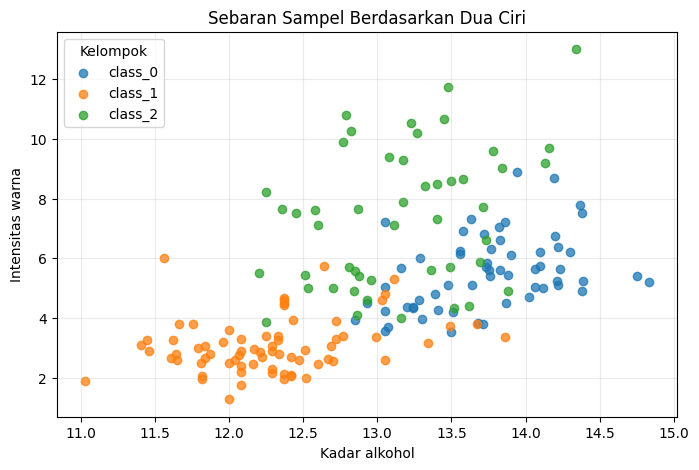

In [3]:
plt.figure(figsize=(8, 5))

for nomor, nama in nama_kelompok.items():
    bagian = target == nomor
    plt.scatter(
        fitur.loc[bagian, "alcohol"],
        fitur.loc[bagian, "color_intensity"],
        label=nama,
        alpha=0.75
    )

plt.xlabel("Kadar alkohol")
plt.ylabel("Intensitas warna")
plt.title("Sebaran Sampel Berdasarkan Dua Ciri")
plt.legend(title="Kelompok")
plt.grid(alpha=0.25)
plt.show()

## 4. Membagi data untuk latihan dan pengujian

Data dibagi menjadi dua bagian. Data latihan digunakan oleh model untuk mempelajari pola, sedangkan data pengujian digunakan untuk memeriksa hasil pada sampel yang tidak dipakai saat pelatihan.

Pembagian dibuat dengan mempertahankan perbandingan kelompok agar hasil pengujian lebih seimbang.

In [4]:
fitur_latih, fitur_uji, target_latih, target_uji = train_test_split(
    fitur,
    target,
    test_size=0.25,
    random_state=ANGKA_ACAK,
    stratify=target
)

print("Jumlah data latihan:", len(fitur_latih))
print("Jumlah data pengujian:", len(fitur_uji))

Jumlah data latihan: 133
Jumlah data pengujian: 45


## 5. Model pertama: K-Nearest Neighbors (KNN)

KNN memperkirakan kelompok sebuah sampel dengan melihat kelompok dari beberapa sampel lain yang paling dekat dengannya. Karena jarak antarfitur bisa memiliki skala yang berbeda, data dinormalisasi terlebih dahulu.

In [5]:
model_knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

model_knn.fit(fitur_latih, target_latih)
hasil_knn = model_knn.predict(fitur_uji)

print("Akurasi KNN:", round(accuracy_score(target_uji, hasil_knn), 4))
print("\nRincian hasil KNN:")
print(classification_report(
    target_uji,
    hasil_knn,
    target_names=data_wine.target_names,
    zero_division=0
))

Akurasi KNN: 0.9778

Rincian hasil KNN:
              precision    recall  f1-score   support

     class_0       0.94      1.00      0.97        15
     class_1       1.00      0.94      0.97        18
     class_2       1.00      1.00      1.00        12

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



## 6. Model kedua: Pohon Keputusan

Pohon Keputusan membuat aturan bertahap berdasarkan nilai fitur. Model ini relatif mudah dijelaskan karena keputusan dapat ditelusuri melalui cabang-cabang pohon.

In [6]:
model_pohon = DecisionTreeClassifier(
    max_depth=4,
    random_state=ANGKA_ACAK
)

model_pohon.fit(fitur_latih, target_latih)
hasil_pohon = model_pohon.predict(fitur_uji)

print("Akurasi Pohon Keputusan:", round(accuracy_score(target_uji, hasil_pohon), 4))
print("\nRincian hasil Pohon Keputusan:")
print(classification_report(
    target_uji,
    hasil_pohon,
    target_names=data_wine.target_names,
    zero_division=0
))

Akurasi Pohon Keputusan: 0.9111

Rincian hasil Pohon Keputusan:
              precision    recall  f1-score   support

     class_0       0.93      0.93      0.93        15
     class_1       0.89      0.89      0.89        18
     class_2       0.92      0.92      0.92        12

    accuracy                           0.91        45
   macro avg       0.91      0.91      0.91        45
weighted avg       0.91      0.91      0.91        45



### Melihat bentuk pohon

Diagram berikut menunjukkan sebagian aturan yang dipelajari model. Kedalaman pohon dibatasi supaya gambar lebih mudah dibaca.

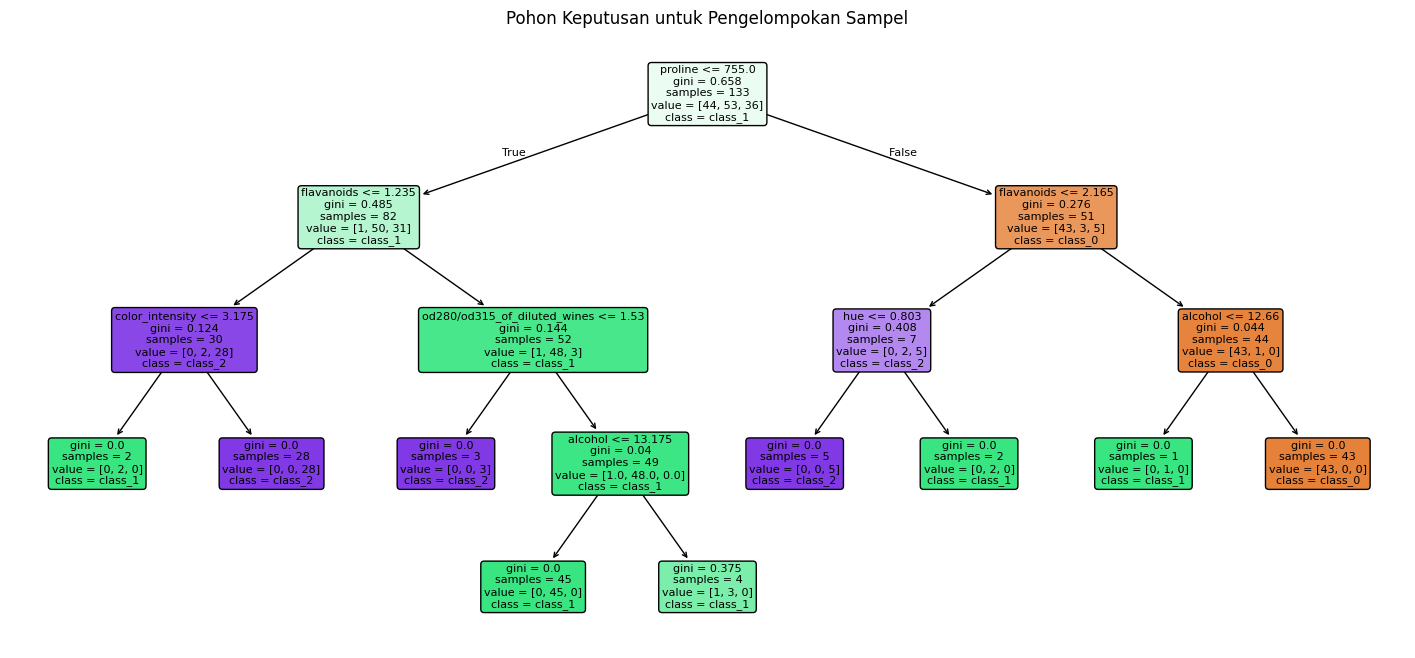

In [7]:
plt.figure(figsize=(18, 8))
plot_tree(
    model_pohon,
    feature_names=list(fitur.columns),
    class_names=list(data_wine.target_names),
    filled=True,
    rounded=True,
    fontsize=8
)
plt.title("Pohon Keputusan untuk Pengelompokan Sampel")
plt.show()

## 7. Model ketiga: Regresi Logistik

Regresi Logistik menghitung peluang sebuah sampel masuk ke kelompok tertentu. Walaupun namanya mengandung kata regresi, metode ini juga sering digunakan untuk klasifikasi.

In [8]:
model_logistik = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=3000, random_state=ANGKA_ACAK)
)

model_logistik.fit(fitur_latih, target_latih)
hasil_logistik = model_logistik.predict(fitur_uji)

print("Akurasi Regresi Logistik:", round(accuracy_score(target_uji, hasil_logistik), 4))
print("\nRincian hasil Regresi Logistik:")
print(classification_report(
    target_uji,
    hasil_logistik,
    target_names=data_wine.target_names,
    zero_division=0
))

Akurasi Regresi Logistik: 1.0

Rincian hasil Regresi Logistik:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        15
     class_1       1.00      1.00      1.00        18
     class_2       1.00      1.00      1.00        12

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



## 8. Membandingkan hasil model

Akurasi menunjukkan bagian prediksi yang benar dari seluruh data pengujian. Nilai yang tinggi belum tentu cukup untuk menilai model, sehingga laporan klasifikasi juga perlu diperhatikan.

In [9]:
daftar_model = {
    "KNN": hasil_knn,
    "Pohon Keputusan": hasil_pohon,
    "Regresi Logistik": hasil_logistik
}

ringkasan = pd.DataFrame([
    {
        "Metode": nama,
        "Akurasi": accuracy_score(target_uji, prediksi)
    }
    for nama, prediksi in daftar_model.items()
]).sort_values("Akurasi", ascending=False)

display(ringkasan.round(4))

,Metode,Akurasi
2,Regresi Logistik,1.0000
0,KNN,0.9778
1,Pohon Keputusan,0.9111


## 9. Membaca matriks kebingungan

Matriks kebingungan membandingkan kelompok sebenarnya dengan kelompok hasil prediksi. Nilai pada diagonal menunjukkan prediksi yang benar, sedangkan nilai di luar diagonal menunjukkan sampel yang salah dikelompokkan.

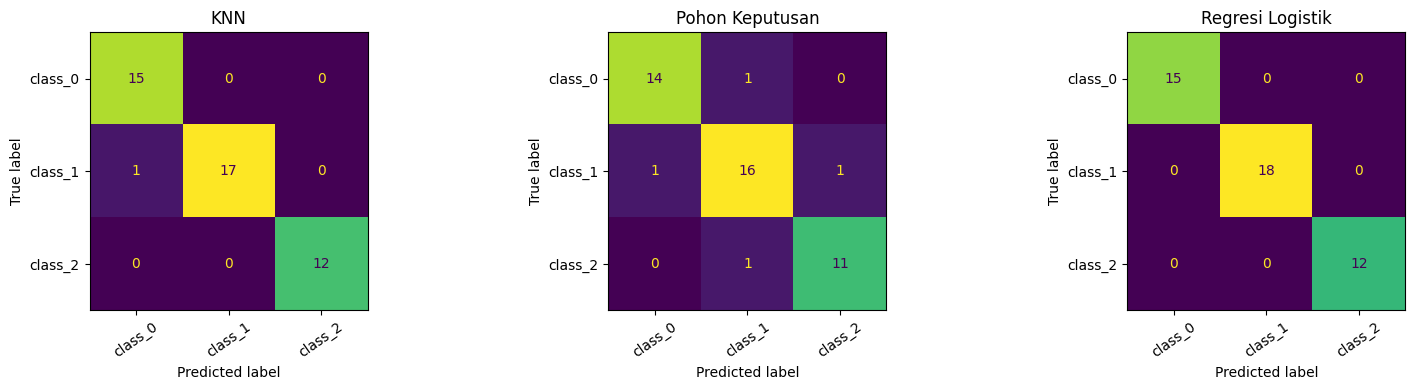

In [10]:
fig, sumbu = plt.subplots(1, 3, figsize=(16, 4))

for ax, (nama, prediksi) in zip(sumbu, daftar_model.items()):
    ConfusionMatrixDisplay.from_predictions(
        target_uji,
        prediksi,
        display_labels=data_wine.target_names,
        ax=ax,
        colorbar=False
    )
    ax.set_title(nama)
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

## 10. Mencoba prediksi pada satu sampel

Di bawah ini kita mengambil satu baris dari data pengujian, lalu meminta model memperkirakan kelompoknya. Kita tampilkan kelompok sebenarnya dan hasil prediksi untuk dibandingkan.

In [11]:
nomor_sampel = 0
sampel = fitur_uji.iloc[[nomor_sampel]]
kelompok_sebenarnya = nama_kelompok[int(target_uji.iloc[nomor_sampel])]

print("Kelompok sebenarnya:", kelompok_sebenarnya)
print("\nHasil perkiraan:")

for nama, model in [
    ("KNN", model_knn),
    ("Pohon Keputusan", model_pohon),
    ("Regresi Logistik", model_logistik)
]:
    hasil = int(model.predict(sampel)[0])
    print(f"{nama}: {nama_kelompok[hasil]}")

Kelompok sebenarnya: class_0

Hasil perkiraan:
KNN: class_0
Pohon Keputusan: class_0
Regresi Logistik: class_0


## 11. Kesimpulan

Dari latihan ini, beberapa hal yang dapat diambil adalah:

- Klasifikasi digunakan untuk memperkirakan label atau kelompok suatu data.
- KNN menentukan kelompok berdasarkan sampel lain yang paling dekat.
- Pohon Keputusan menggunakan serangkaian aturan berdasarkan fitur.
- Regresi Logistik memperkirakan peluang keanggotaan kelompok.
- Pembagian data latihan dan pengujian membantu menilai kemampuan model pada data yang belum pernah dilihat.
- Akurasi sebaiknya dibaca bersama matriks kebingungan dan laporan klasifikasi.

## Pertanyaan latihan

1. Metode mana yang menghasilkan akurasi tertinggi pada percobaan ini?
2. Mengapa data perlu dibagi menjadi data latihan dan data pengujian?
3. Apa arti nilai di luar diagonal pada matriks kebingungan?
4. Mengapa normalisasi digunakan pada KNN dan Regresi Logistik?
5. Apa kelebihan Pohon Keputusan dibandingkan metode lain dalam hal penjelasan hasil?

**Catatan:** hasil angka dapat berbeda jika pembagian data, parameter, atau versi pustaka diubah.